# Гамма-кванты и адронный фон в телескопе MAGIC — вариант 10
**Набор данных:** UCI MAGIC Gamma Telescope (Монте-Карло, Corsika). **Цель:** `gamma` (сигнал) против `hadron` (фон).
**Модели:** kNN, SVM (линейный и RBF), логистическая регрессия; стандартизация обязательна и находится внутри конвейера.
**Проверка:** стратифицированная кросс-валидация; отдельный разбор ROC при FPR ≤ 0.1.
**Результат:** ROC основных моделей, сравнение при FPR < 0.1, объяснение, почему одной accuracy недостаточно.

## 1. Данные и физический смысл

Черенковский телескоп регистрирует вспышку света от атмосферного ливня. Изображение ливня на камере описывают эллипсом (параметры Хилласа). Гамма-кванты дают компактные вытянутые эллипсы, ось которых направлена к центру камеры; адроны (космические лучи) — более широкие и «рваные» ливни с произвольной ориентацией.

| Признак | Смысл | Единицы |
|---|---|---|
| `fLength`, `fWidth` | большая и малая оси эллипса | мм |
| `fSize` | десятичный логарифм суммарного содержимого пикселей | lg(фотонов) |
| `fConc`, `fConc1` | доля двух самых ярких пикселей / самого яркого от `fSize` | – |
| `fAsym` | расстояние от самого яркого пикселя до центра, проекция на большую ось | мм |
| `fM3Long`, `fM3Trans` | кубический корень третьего момента вдоль большой / малой оси | мм |
| `fAlpha` | угол большой оси с направлением на центр камеры | градусы |
| `fDist` | расстояние от центра камеры до центра эллипса | мм |

**Важно из описания набора.** (1) Класс `h` в данных занижен (в реальных наблюдениях фон — большинство). (2) Принять фон за сигнал хуже, чем пропустить сигнал, поэтому классификаторы сравнивают по ROC в точках, где доля принятого фона FPR равна 0.01, 0.02, 0.05, 0.1, 0.2.

**Что ожидаем физически (проверим в §2).** У гаммы малые `fAlpha` (источник «смотрит» в центр камеры), малые `fWidth` и `fLength` (компактный ливень), большая концентрация `fConc`.

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, roc_curve, make_scorer, accuracy_score, balanced_accuracy_score

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})
SEED = 42
cols = ['fLength', 'fWidth', 'fSize', 'fConc', 'fConc1', 'fAsym', 'fM3Long', 'fM3Trans', 'fAlpha', 'fDist', 'class']
raw = pd.read_csv('magic04.data', header=None, names=cols)       # файл рядом с ноутбуком
print('форма:', raw.shape, '| пропусков:', int(raw.isna().sum().sum()))
dup = raw.duplicated(keep=False)
print('строк в дубликатах:', int(dup.sum()), '| классов внутри групп дубликатов (макс.):',
      raw[dup].groupby(cols[:-1])['class'].nunique().max())

форма: (19020, 11) | пропусков: 0
строк в дубликатах: 230 | классов внутри групп дубликатов (макс.): 1


Дубликаты (одинаковые 10 признаков) всегда имеют одну метку. Если оставить их, копии одного события окажутся и в обучающей, и в проверочной части CV, что даёт утечку, поэтому точные дубликаты удаляем **до** разбиения.

In [2]:
df = raw.drop_duplicates().reset_index(drop=True)
feats = cols[:-1]
y = (df['class'] == 'g').astype(int).values        # 1 = gamma (сигнал, «положительный»), 0 = hadron (фон)
X = df[feats]
print('после удаления дубликатов:', len(df), '| доля gamma: %.3f' % y.mean(), '| accuracy тривиального «всегда gamma»: %.3f' % y.mean())
df.describe().T.round(2)

после удаления дубликатов: 18905 | доля gamma: 0.652 | accuracy тривиального «всегда gamma»: 0.652


,count,mean,std,min,25%,50%,75%,max
fLength,18905.0,53.16,42.26,4.28,24.36,37.13,69.98,334.18
fWidth,18905.0,22.15,18.30,0.00,11.87,17.14,24.71,256.38
fSize,18905.0,2.82,0.47,1.94,2.48,2.74,3.10,5.32
fConc,18905.0,0.38,0.18,0.01,0.24,0.35,0.50,0.89
fConc1,18905.0,0.21,0.11,0.00,0.13,0.20,0.28,0.68
fAsym,18905.0,-4.18,59.01,-457.92,-20.48,4.06,24.13,575.24
fM3Long,18905.0,10.62,50.90,-331.78,-12.77,15.34,35.87,238.32
fM3Trans,18905.0,0.26,20.78,-205.89,-10.84,0.75,10.95,179.85
fAlpha,18905.0,27.55,26.08,0.00,5.52,17.53,45.70,90.00
fDist,18905.0,193.71,74.69,1.28,142.27,191.83,240.41,495.56


## 2. Разведочный анализ

Обязательные предметные графики: диаграммы `fLength`–`fWidth` и `fAlpha`–`fSize` с цветом по классу.

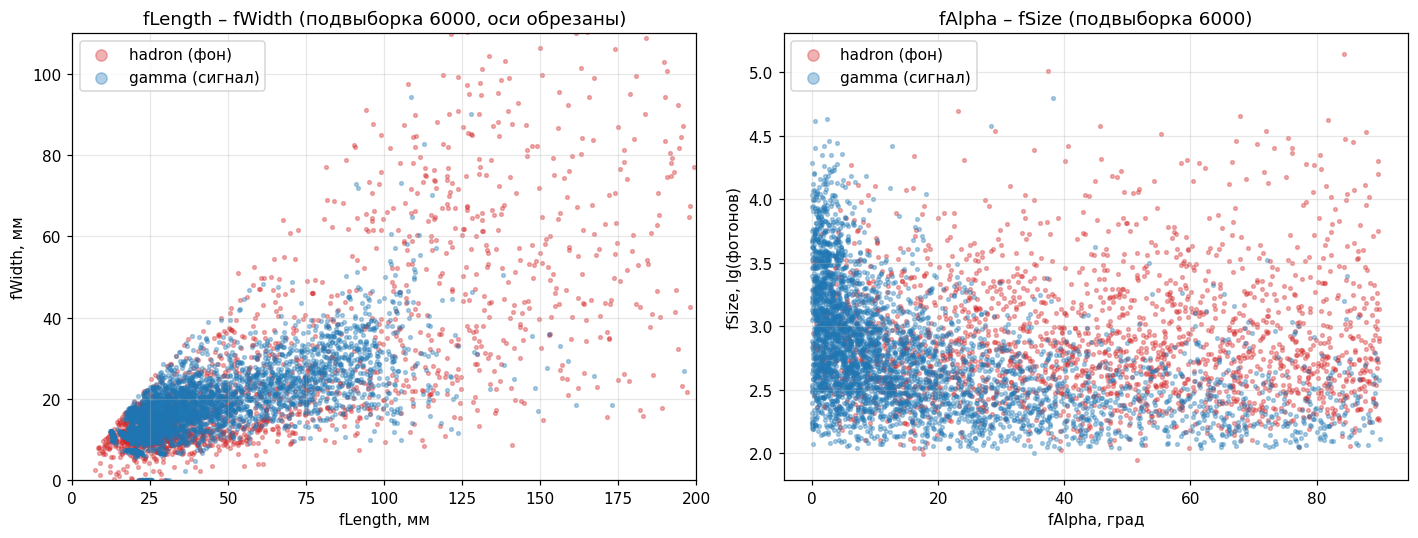

In [3]:
sub = df.sample(6000, random_state=SEED)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
for lab, c, nm in [('h', 'tab:red', 'hadron (фон)'), ('g', 'tab:blue', 'gamma (сигнал)')]:
    s = sub[sub['class'] == lab]
    ax[0].scatter(s.fLength, s.fWidth, s=6, alpha=.35, c=c, label=nm)
    ax[1].scatter(s.fAlpha, s.fSize, s=6, alpha=.35, c=c, label=nm)
ax[0].set_xlim(0, 200); ax[0].set_ylim(0, 110)
ax[0].set_xlabel('fLength, мм'); ax[0].set_ylabel('fWidth, мм'); ax[0].set_title('fLength – fWidth (подвыборка 6000, оси обрезаны)')
ax[1].set_xlabel('fAlpha, град'); ax[1].set_ylabel('fSize, lg(фотонов)'); ax[1].set_title('fAlpha – fSize (подвыборка 6000)')
for a in ax: a.legend(markerscale=3)
plt.tight_layout(); plt.show()

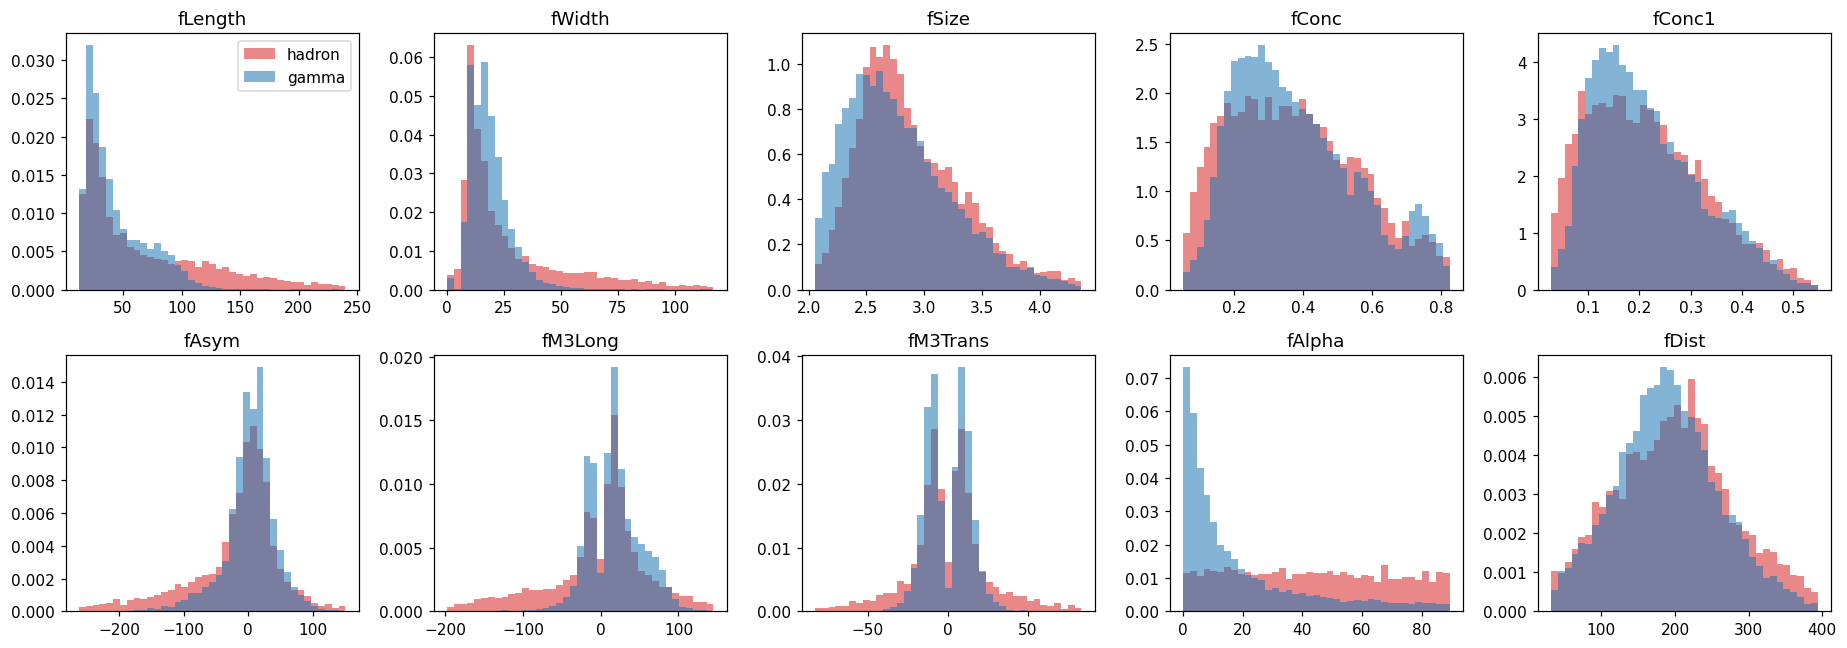

,AUC (gamma=1),"разделимость max(AUC,1−AUC)",gamma имеет
fAlpha,0.215,0.785,меньшие значения
fLength,0.385,0.615,меньшие значения
fAsym,0.580,0.580,бо́льшие значения
fM3Long,0.578,0.578,бо́льшие значения
fSize,0.427,0.573,меньшие значения
fWidth,0.456,0.544,меньшие значения
fDist,0.465,0.535,меньшие значения
fConc,0.515,0.515,бо́льшие значения
fConc1,0.509,0.509,бо́льшие значения
fM3Trans,0.499,0.501,меньшие значения


In [4]:
fig, axs = plt.subplots(2, 5, figsize=(17, 6))
for a, f in zip(axs.ravel(), feats):
    lo, hi = np.percentile(df[f], [0.5, 99.5]); bins = np.linspace(lo, hi, 40)
    a.hist(df.loc[df['class'] == 'h', f], bins=bins, alpha=.55, density=True, color='tab:red', label='hadron')
    a.hist(df.loc[df['class'] == 'g', f], bins=bins, alpha=.55, density=True, color='tab:blue', label='gamma')
    a.set_title(f); a.grid(False)
axs[0, 0].legend(); plt.tight_layout(); plt.show()

uni = pd.DataFrame({'AUC (gamma=1)': {f: roc_auc_score(y, df[f]) for f in feats}})
uni['разделимость max(AUC,1−AUC)'] = np.maximum(uni.iloc[:, 0], 1 - uni.iloc[:, 0])
uni['gamma имеет'] = np.where(uni.iloc[:, 0] > .5, 'бо́льшие значения', 'меньшие значения')
uni.sort_values('разделимость max(AUC,1−AUC)', ascending=False).round(3)

**Что видно.** Лучше всего по одному признаку разделяет `fAlpha` (AUC ≈ 0.21: у гаммы значения заметно меньше — согласуется с физикой), затем `fLength` (у гаммы меньше — тоже согласуется). `fWidth` слегка меньше у гаммы, а ожидание про бо́льшую концентрацию `fConc` подтверждается лишь слабо (AUC ≈ 0.52): по отдельности эти признаки почти не различают классы. Ни один признак в одиночку не даёт чистого разделения: классы перекрываются, поэтому нужны многомерные модели. `fAsym`, `fM3Long`, `fM3Trans` знакопеременные и имеют тяжёлые хвосты — стандартизация необходима, но не устранит выбросы.

## 3. Метрики и протокол проверки

**Положительный класс — gamma.** `TPR` — доля принятых гамма-событий, `FPR` — доля фона, принятого как сигнал. По описанию набора важны точки ROC при FPR ∈ {0.01, 0.02, 0.05, 0.1, 0.2}.

Метрики для сравнения:
* **ROC-AUC** (весь диапазон);
* **pAUC₀.₁** — стандартизованная частичная площадь при FPR ≤ 0.1 (`roc_auc_score(max_fpr=0.1)`, поправка McClish: 0.5 — случайный классификатор, 1 — идеальный);
* **TPR при фиксированных FPR** (0.01 … 0.2);
* accuracy / balanced accuracy — только для контраста в §8.

**Протокол.** Тест 25 % (стратифицированно, один раз в конце). На обучении — стратифицированная 5-fold CV; гиперпараметры выбираются по **pAUC₀.₁** (метрика под задачу, а не accuracy). Стандартизация, полиномы — внутри `Pipeline`, т.е. пересчитываются на каждом фолде.

In [5]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=.25, stratify=y, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
print('train/test:', len(Xtr), len(Xte), '| доля gamma train/test: %.3f / %.3f' % (ytr.mean(), yte.mean()))

FPR_LEVELS = [0.01, 0.02, 0.05, 0.1, 0.2]
def tpr_at(y_true, s, f):
    fpr, tpr, _ = roc_curve(y_true, s); return float(np.interp(f, fpr, tpr))
def roc_metrics(y_true, s):
    d = {'AUC': roc_auc_score(y_true, s), 'pAUC0.1': roc_auc_score(y_true, s, max_fpr=0.1)}
    d.update({f'TPR@{f}': tpr_at(y_true, s, f) for f in FPR_LEVELS}); return d
pauc_scorer = make_scorer(roc_auc_score, max_fpr=0.1, response_method=('decision_function', 'predict_proba'))

def score_of(est, X_):
    # непрерывная оценка «похожести на gamma»: decision_function или P(gamma)
    return est.decision_function(X_) if hasattr(est, 'decision_function') else est.predict_proba(X_)[:, 1]

train/test: 14178 4727 | доля gamma train/test: 0.652 / 0.652


## 4. Модели и подбор гиперпараметров

* **Базовая:** константный классификатор (априорная вероятность) — ROC = диагональ.
* **Логистическая регрессия** (линейная модель с вероятностями) и она же на полиномах 2-й степени (нелинейность — в признаках, модель линейна по параметрам).
* **Линейный SVM** (`LinearSVC`) и **SVM с RBF-ядром**.
* **kNN** с евклидовой метрикой на стандартизованных признаках; число соседей и веса — по CV.

In [24]:
std = lambda *rest: Pipeline([('sc', StandardScaler()), *rest])
specs = {
 'Базовая (константа)':   (Pipeline([('m', DummyClassifier(strategy='prior'))]), None),
 'Логистическая регрессия': (std(('m', LogisticRegression(max_iter=5000))), {'m__C': np.logspace(-3, 2, 6)}),
 'Лог. регрессия, полином-2': (Pipeline([('sc0', StandardScaler()), ('poly', PolynomialFeatures(2, include_bias=False)),
                                         ('sc', StandardScaler()), ('m', LogisticRegression(max_iter=5000))]),
                               {'m__C': np.logspace(-3, 1, 5)}),
'Линейный SVM': (std(('m', LinearSVC(dual=False, max_iter=50000))), {'m__C': np.logspace(-3, 1, 5)}),
'SVM, RBF-ядро':         (std(('m', SVC(kernel='rbf'))), {'m__C': [1, 3, 10], 'm__gamma': [0.03, 0.1, 0.3]}),
'kNN': (std(('m', KNeighborsClassifier(weights='distance'))), {'m__n_neighbors': [25, 51, 101, 201]}),
}
fitted, best_params, oof_scores = {}, {}, {}
for name, (pipe, grid) in specs.items():
    if grid:
        gs = GridSearchCV(pipe, grid, cv=cv, scoring=pauc_scorer, n_jobs=-1, refit=True).fit(Xtr, ytr)
        est, best_params[name] = gs.best_estimator_, {k.split('__')[1]: (round(float(v), 4) if not isinstance(v, str) else v) for k, v in gs.best_params_.items()}
    else:
        est, best_params[name] = pipe.fit(Xtr, ytr), {}
    method = 'decision_function' if hasattr(est, 'decision_function') else 'predict_proba'
    s = cross_val_predict(clone(est), Xtr, ytr, cv=cv, method=method)
    oof_scores[name] = s[:, 1] if s.ndim > 1 else s
    fitted[name] = est
    print(f'{name:28s}', best_params[name])

Базовая (константа)          {}
Логистическая регрессия      {'C': 0.001}
Лог. регрессия, полином-2    {'C': 0.001}
Линейный SVM                 {'C': 0.001}
SVM, RBF-ядро                {'C': 1.0, 'gamma': 0.03}
kNN                          {'n_neighbors': 25.0}


kNN                          {'n_neighbors': 51.0, 'weights': 'distance'}


## 5. Результаты: кросс-валидация (out-of-fold) и тест

CV-оценки считаются по объединённым out-of-fold предсказаниям обучающей части. Они слегка оптимистичны, поскольку те же фолды использовались для выбора гиперпараметров. Тест не использовался ни для чего, кроме этой таблицы.

In [25]:
cv_tab = pd.DataFrame({n: roc_metrics(ytr, s) for n, s in oof_scores.items()}).T
te_scores = {n: score_of(m, Xte) for n, m in fitted.items()}
te_tab = pd.DataFrame({n: roc_metrics(yte, s) for n, s in te_scores.items()}).T
print('CV (out-of-fold, обучающая часть):'); display(cv_tab.round(3))
print('Тест:'); display(te_tab.round(3))

CV (out-of-fold, обучающая часть):


,AUC,pAUC0.1,TPR@0.01,TPR@0.02,TPR@0.05,TPR@0.1,TPR@0.2
Базовая (константа),0.500,0.500,0.010,0.020,0.050,0.100,0.200
Логистическая регрессия,0.835,0.615,0.071,0.119,0.292,0.485,0.729
"Лог. регрессия, полином-2",0.892,0.715,0.237,0.315,0.489,0.665,0.823
Линейный SVM,0.840,0.625,0.084,0.144,0.304,0.500,0.738
"SVM, RBF-ядро",0.908,0.694,0.073,0.197,0.465,0.704,0.882
kNN,0.901,0.724,0.258,0.360,0.520,0.675,0.834


Тест:


,AUC,pAUC0.1,TPR@0.01,TPR@0.02,TPR@0.05,TPR@0.1,TPR@0.2
Базовая (константа),0.500,0.500,0.010,0.020,0.050,0.100,0.200
Логистическая регрессия,0.831,0.607,0.043,0.098,0.258,0.474,0.722
"Лог. регрессия, полином-2",0.895,0.722,0.250,0.330,0.503,0.671,0.827
Линейный SVM,0.834,0.612,0.045,0.086,0.303,0.469,0.726
"SVM, RBF-ядро",0.909,0.691,0.068,0.184,0.454,0.717,0.876
kNN,0.902,0.718,0.281,0.344,0.512,0.651,0.834


In [26]:
# разброс pAUC0.1 по фолдам CV для финальных гиперпараметров (устойчивость выбора)
fold_rows = {}
for n, m in fitted.items():
    if n.startswith('Базовая'): continue
    v = []
    for tr_i, va_i in cv.split(Xtr, ytr):
        mm = clone(m).fit(Xtr.iloc[tr_i], ytr[tr_i]); v.append(roc_auc_score(ytr[va_i], score_of(mm, Xtr.iloc[va_i]), max_fpr=0.1))
    fold_rows[n] = {'pAUC0.1 среднее': np.mean(v), 'sd по фолдам': np.std(v, ddof=1), 'min': np.min(v), 'max': np.max(v)}
pd.DataFrame(fold_rows).T.round(3)

,pAUC0.1 среднее,sd по фолдам,min,max
Логистическая регрессия,0.615,0.005,0.609,0.624
"Лог. регрессия, полином-2",0.716,0.008,0.706,0.728
Линейный SVM,0.625,0.007,0.619,0.636
"SVM, RBF-ядро",0.694,0.023,0.663,0.721
kNN,0.724,0.012,0.709,0.740


## 6. ROC-кривые и увеличенная область FPR ≤ 0.1

Слева — вся ROC, в центре — увеличенная область FPR ≤ 0.1 (линейная шкала), справа — та же область в логарифмической шкале по FPR. Пунктиром отмечены рабочие точки из описания набора (0.01, 0.02, 0.05, 0.1, 0.2).

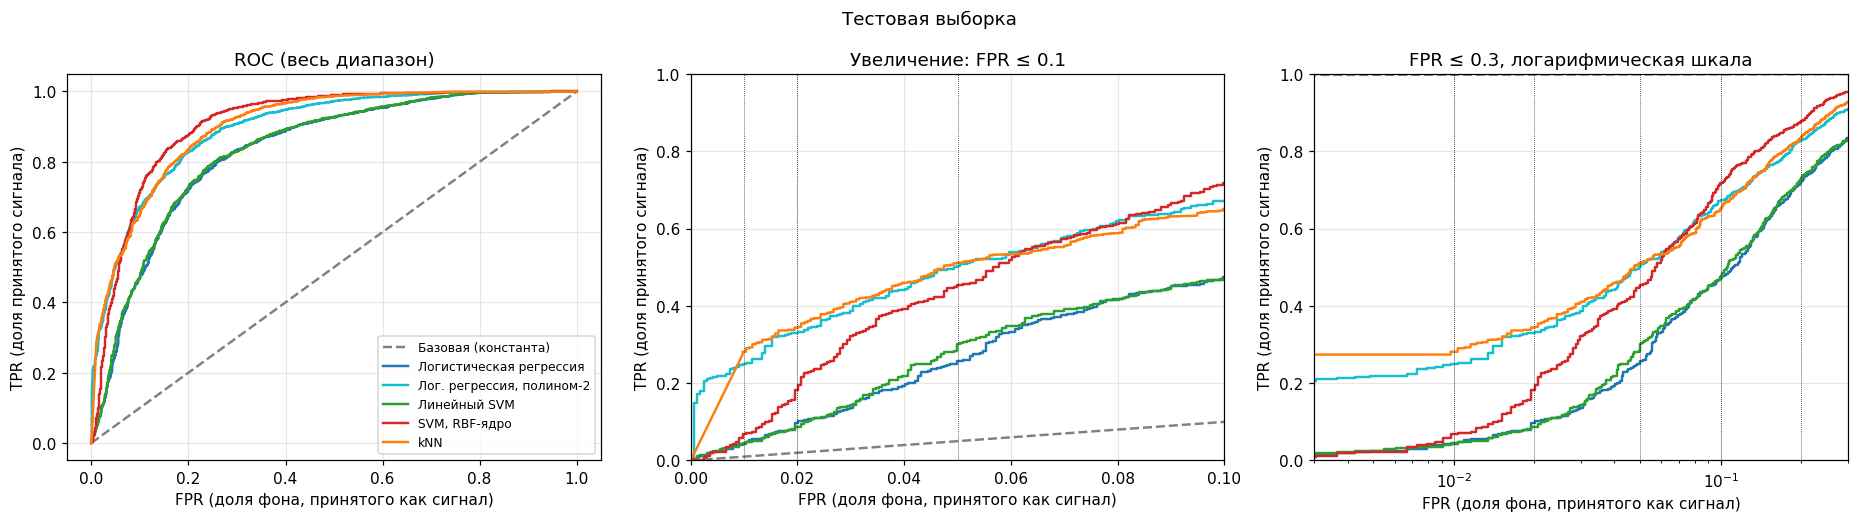

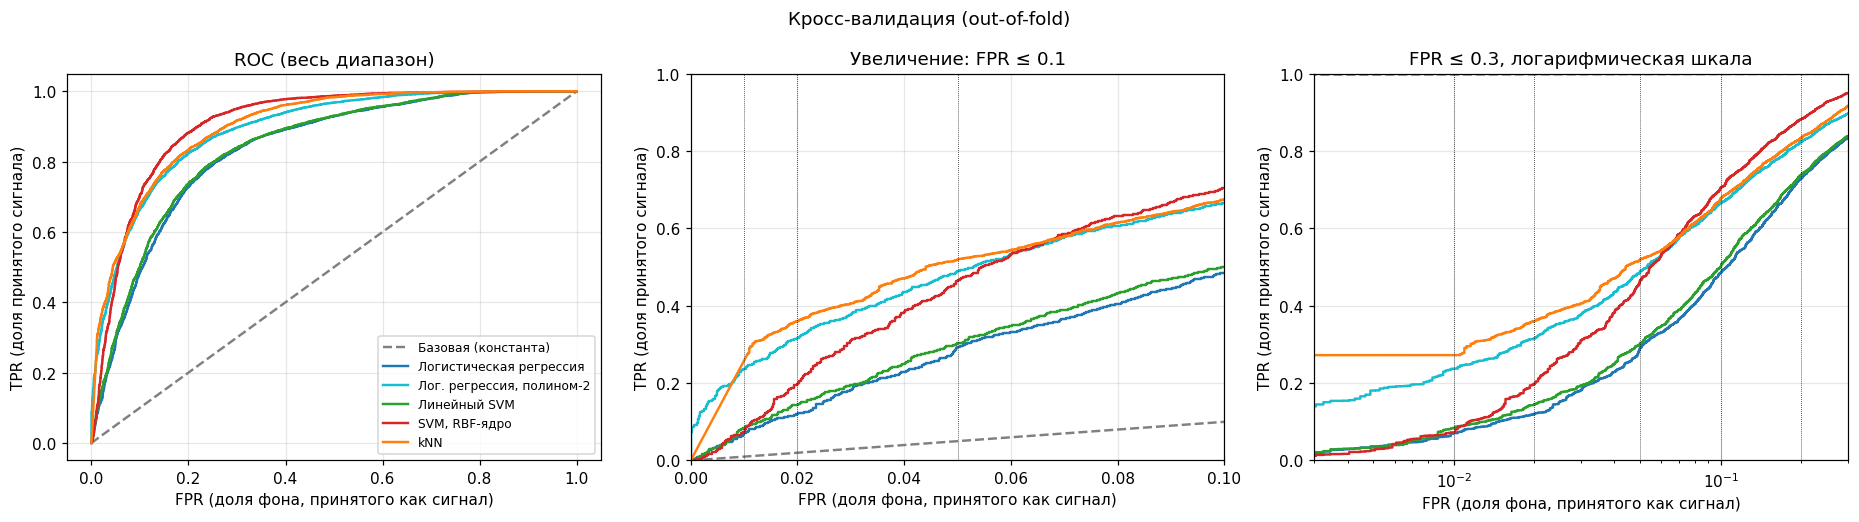

In [27]:
colors = {'Базовая (константа)': 'gray', 'Логистическая регрессия': 'tab:blue', 'Лог. регрессия, полином-2': 'tab:cyan',
          'Линейный SVM': 'tab:green', 'SVM, RBF-ядро': 'tab:red', 'kNN': 'tab:orange'}
def plot_roc(scores, y_true, title):
    fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
    for n, s in scores.items():
        fpr, tpr, _ = roc_curve(y_true, s)
        if n.startswith('Базовая'): fpr, tpr = np.array([0, 1.]), np.array([0, 1.])   # константа = диагональ
        kw = dict(c=colors[n], lw=1.6, ls='--' if n.startswith('Базовая') else '-', label=n)
        ax[0].plot(fpr, tpr, **kw); ax[1].plot(fpr, tpr, **kw); ax[2].plot(fpr, tpr, **kw)
    for a in ax[1:]:
        for f in FPR_LEVELS: a.axvline(f, c='k', lw=.5, ls=':')
    ax[0].set_title('ROC (весь диапазон)'); ax[0].legend(fontsize=8, loc='lower right')
    ax[1].set_xlim(0, .1); ax[1].set_ylim(0, 1); ax[1].set_title('Увеличение: FPR ≤ 0.1')
    ax[2].set_xscale('log'); ax[2].set_xlim(3e-3, .3); ax[2].set_ylim(0, 1); ax[2].set_title('FPR ≤ 0.3, логарифмическая шкала')
    for a in ax: a.set_xlabel('FPR (доля фона, принятого как сигнал)'); a.set_ylabel('TPR (доля принятого сигнала)')
    fig.suptitle(title); plt.tight_layout(); plt.show()
plot_roc(te_scores, yte, 'Тестовая выборка')
plot_roc(oof_scores, ytr, 'Кросс-валидация (out-of-fold)')

In [28]:
print(best_params['kNN'])

{'n_neighbors': 25.0}


### Достоверность различий при малых FPR

На тесте около 1600 фоновых событий, поэтому при FPR = 0.01 «принятого фона» всего ≈ 16 событий — оценка TPR там шумная. Оценим разброс парным бутстрэпом по тестовым событиям (B = 300) и разности с лучшей по pAUC моделью.

In [29]:
rs = np.random.default_rng(SEED); B = 300; names = [n for n in te_scores if not n.startswith('Базовая')]
S = {n: te_scores[n] for n in names}
bs = {n: {'pAUC0.1': [], 'TPR@0.01': [], 'TPR@0.05': []} for n in names}
n_te = len(yte)
for _ in range(B):
    idx = rs.integers(0, n_te, n_te); yb = yte[idx]
    for n in names:
        sb = S[n][idx]
        bs[n]['pAUC0.1'].append(roc_auc_score(yb, sb, max_fpr=0.1)); bs[n]['TPR@0.01'].append(tpr_at(yb, sb, .01)); bs[n]['TPR@0.05'].append(tpr_at(yb, sb, .05))
best_te = max(names, key=lambda n: te_tab.loc[n, 'pAUC0.1'])
rows = {}
for n in names:
    r = {}
    for k in ['pAUC0.1', 'TPR@0.01', 'TPR@0.05']:
        v = np.array(bs[n][k]); r[f'{k} [95% ДИ]'] = f'{np.mean(v):.3f} [{np.percentile(v, 2.5):.3f}; {np.percentile(v, 97.5):.3f}]'
        d = v - np.array(bs[best_te][k]); r[f'Δ{k} к лучшей'] = '—' if n == best_te else f'{d.mean():+.3f} [{np.percentile(d, 2.5):+.3f}; {np.percentile(d, 97.5):+.3f}]'
    rows[n] = r
print('Лучшая по pAUC0.1 на тесте:', best_te)
pd.DataFrame(rows).T

Лучшая по pAUC0.1 на тесте: Лог. регрессия, полином-2


,pAUC0.1 [95% ДИ],ΔpAUC0.1 к лучшей,TPR@0.01 [95% ДИ],ΔTPR@0.01 к лучшей,TPR@0.05 [95% ДИ],ΔTPR@0.05 к лучшей
Логистическая регрессия,0.608 [0.588; 0.628],-0.114 [-0.131; -0.098],0.047 [0.024; 0.073],-0.202 [-0.251; -0.165],0.261 [0.191; 0.340],-0.241 [-0.305; -0.177]
"Лог. регрессия, полином-2",0.722 [0.703; 0.739],—,0.249 [0.215; 0.296],—,0.502 [0.450; 0.539],—
Линейный SVM,0.613 [0.593; 0.634],-0.108 [-0.124; -0.094],0.045 [0.028; 0.069],-0.204 [-0.248; -0.172],0.295 [0.228; 0.360],-0.207 [-0.261; -0.157]
"SVM, RBF-ядро",0.692 [0.668; 0.719],-0.030 [-0.047; -0.013],0.064 [0.021; 0.111],-0.184 [-0.233; -0.134],0.453 [0.405; 0.520],-0.049 [-0.097; +0.006]
kNN,0.719 [0.699; 0.736],-0.003 [-0.022; +0.015],0.267 [0.180; 0.320],+0.018 [-0.071; +0.084],0.506 [0.453; 0.540],+0.004 [-0.044; +0.056]


**Как читать.** Если ДИ разности содержит 0, различие между моделью и лучшей при этом показателе нельзя считать надёжным: на тесте просто мало событий в области малых FPR.

## 7. Рабочая точка: перенос порога с обучения на тест

На практике порог выбирают по обучающим данным. Берём порог, дающий FPR = 0.05 на out-of-fold оценках фона, и смотрим, какие FPR и TPR получаются на тесте.

In [30]:
rows = []
for n in names:
    thr = np.quantile(oof_scores[n][ytr == 0], 1 - 0.05)
    pred = te_scores[n] >= thr
    rows.append({'модель': n, 'целевой FPR': .05, 'FPR на тесте': pred[yte == 0].mean(), 'TPR на тесте': pred[yte == 1].mean()})
pd.DataFrame(rows).set_index('модель').round(3)

,целевой FPR,FPR на тесте,TPR на тесте
модель,,,
Логистическая регрессия,0.05,0.063,0.352
"Лог. регрессия, полином-2",0.05,0.058,0.523
Линейный SVM,0.05,0.054,0.314
"SVM, RBF-ядро",0.05,0.055,0.469
kNN,0.05,0.051,0.512


Расхождение фактического FPR с целевым — отдельная проблема: для kNN и SVM шкала оценок на out-of-fold и на модели, обученной на всей обучающей выборке, немного различается. Поэтому порог лучше калибровать на отдельной валидационной части и проверять FPR интервалом, а не одним числом.

## 8. Почему одной accuracy недостаточно

1. **Классы несбалансированы, а их доля искусственная.** В данных 65 % gamma, но в реальных наблюдениях фон — большинство. Accuracy зависит от доли классов, которая в этом наборе выбрана технически; ROC и TPR при фиксированном FPR от неё не зависят.
2. **Ошибки не равноценны.** Принять фон за сигнал хуже, чем пропустить сигнал (описание набора). Accuracy считает их одинаково.
3. **Порог, максимизирующий accuracy, лежит в «неправильной» области ROC.** Ниже видно, какой FPR он даёт.
4. **Одинаковая accuracy скрывает разные TPR при малых FPR.**
5. **Precision (чистота сигнала) зависит от доли сигнала.** Ниже — пересчёт по формуле Байеса.

In [31]:
rows = []
for n in names:
    s_oof, s_te = oof_scores[n], te_scores[n]
    thr0 = 0.5 if n == 'kNN' else 0.0                                       # порог «по умолчанию»
    cand = np.unique(np.quantile(s_oof, np.linspace(0.01, 0.99, 197)))
    thr_acc = cand[np.argmax([accuracy_score(ytr, s_oof >= t) for t in cand])]    # порог по accuracy выбран на обучении
    for lab, t in [('по умолчанию', thr0), ('макс. accuracy (по train)', thr_acc)]:
        p = (s_te >= t).astype(int)
        rows.append({'модель': n, 'порог': lab, 'accuracy': accuracy_score(yte, p), 'balanced acc.': balanced_accuracy_score(yte, p),
                     'FPR': p[yte == 0].mean(), 'TPR': p[yte == 1].mean()})
acc_tab = pd.DataFrame(rows).set_index(['модель', 'порог']).round(3)
print('Тривиальный «всегда gamma»: accuracy = %.3f, FPR = 1.0' % yte.mean())
acc_tab

Тривиальный «всегда gamma»: accuracy = 0.652, FPR = 1.0


accuracy  balanced acc.  \
модель                    порог                                                
Логистическая регрессия   по умолчанию                  0.779          0.715   
                          макс. accuracy (по train)     0.788          0.758   
Лог. регрессия, полином-2 по умолчанию                  0.816          0.750   
                          макс. accuracy (по train)     0.838          0.812   
Линейный SVM              по умолчанию                  0.788          0.739   
                          макс. accuracy (по train)     0.788          0.759   
SVM, RBF-ядро             по умолчанию                  0.864          0.823   
                          макс. accuracy (по train)     0.868          0.841   
kNN                       по умолчанию                  0.841          0.787   
                          макс. accuracy (по train)     0.848          0.810   

                                                       FPR    TPR  
модель                    порог                                    
Логистическая регрессия   по умолчанию               0.498  0.927  
                          макс. accuracy (по train)  0.342  0.857  
Лог. регрессия, полином-2 по умолчанию               0.466  0.966  
                          макс. accuracy (по train)  0.276  0.899  
Линейный SVM              по умолчанию               0.425  0.902  
                          макс. accuracy (по train)  0.338  0.856  
SVM, RBF-ядро             по умолчанию               0.310  0.957  
                          макс. accuracy (по train)  0.246  0.928  
kNN                       по умолчанию               0.389  0.964  
                          макс. accuracy (по train)  0.316  0.936

In [32]:
# чистота сигнала (precision) при том же TPR/FPR, но разной доле сигнала в потоке событий
m = best_te
rows = []
for f in [0.01, 0.05, 0.1]:
    tpr = te_tab.loc[m, f'TPR@{f}']
    for pi in [0.65, 0.10, 0.01]:
        rows.append({'FPR': f, 'TPR (тест)': round(tpr, 3), 'доля gamma в потоке': pi, 'precision': round(tpr * pi / (tpr * pi + f * (1 - pi)), 3)})
print('Модель:', m, '(precision = TPR·π / (TPR·π + FPR·(1−π)))')
pd.DataFrame(rows).pivot(index=['FPR', 'TPR (тест)'], columns='доля gamma в потоке', values='precision')

Модель: Лог. регрессия, полином-2 (precision = TPR·π / (TPR·π + FPR·(1−π)))


,доля gamma в потоке,0.01,0.10,0.65
FPR,TPR (тест),,,
0.01,0.250,0.201,0.735,0.979
0.05,0.503,0.092,0.528,0.949
0.10,0.671,0.063,0.427,0.926


## 9. Итоги (черновик по результатам запуска, seed = 42 — сверьте числа со своим прогоном и перепишите своими словами)

* **Данные.** 19 020 событий, 10 признаков, 115 точных дубликатов с одинаковой меткой удалены до разбиения (утечка в CV). Классы 65 : 35 (gamma : hadron), но в реальных данных фон преобладает.
* **Какие модели лучше.** По тесту: SVM с RBF-ядром (AUC ≈ 0.925, pAUC₀.₁ ≈ 0.74), затем логистическая регрессия на полиномах 2-й степени (≈ 0.908; 0.72) и kNN (≈ 0.900; 0.72). Линейный SVM и обычная логистическая регрессия практически совпадают и заметно слабее (AUC ≈ 0.83, pAUC₀.₁ ≈ 0.61). Базовая модель — AUC = 0.5.
* **При FPR ≤ 0.1.** Линейные модели пропускают почти весь сигнал в самой строгой точке: TPR ≈ 0.045 при FPR = 0.01 против ≈ 0.20–0.26 у нелинейных. Кривые нелинейных моделей пересекаются: kNN лучше при FPR ≲ 0.04 (TPR@0.01 ≈ 0.26), RBF-SVM — при FPR ≳ 0.05. Бутстрэп-ДИ разностей между RBF-SVM, полиномиальной регрессией и kNN содержат 0, т.е. различия между этими тремя при малых FPR статистически ненадёжны; а отставание линейных моделей надёжно.
* **Рабочая точка.** Порог, выбранный на train под FPR = 0.05, даёт на тесте FPR = 0.044–0.057 — близко к цели, но не точно (§7).
* **Почему accuracy недостаточно.** (1) Доля gamma 65 % выбрана технически, в реальных данных фон преобладает. (2) Ошибки неравноценны. (3) Порог, максимизирующий accuracy, даёт FPR ≈ 0.25–0.34, а допустимые значения — 0.01–0.2 и ниже. (4) Accuracy RBF-SVM и полиномиальной регрессии 0.86–0.87 выглядит прилично, но не говорит ничего о TPR при FPR = 0.01. (5) Чистота сигнала при FPR = 0.05, TPR ≈ 0.52: ≈ 0.95 при доле gamma 65 %, но ≈ 0.54 при 10 % и ≈ 0.10 при 1 % (§8).
* **Ограничения.** Данные смоделированы методом Монте-Карло, реальные наблюдения будут отличаться (шум, фон ночного неба, дрейф калибровки). Оценки при FPR = 0.01 шумные. Гиперпараметры выбирались на тех же фолдах, по которым даны CV-метрики.